# Data Mining Lab Assignment 2
## Book Recommendation System with a Bronze–Silver–Gold Data Lake

**Student:** Nayaab Zameer Qazi  
**Roll number:** LCS2023036

This notebook processes the Book-Crossing dataset through a three-layer data lake and builds an **item-based collaborative filtering** recommender. The recommendation model compares books using cosine similarity over users' explicit ratings.

### Workflow

`Book-Crossing CSVs → Bronze (raw snapshot) → Silver (cleaned tables) → Gold (sparse matrix + aggregates) → Recommendations`

> Run the notebook from top to bottom in Google Colab. The raw data and layer outputs are created in the Colab runtime; they do not need to be uploaded separately to GitHub unless your instructor asks for them.

## 0. Environment and imports

The dataset is downloaded automatically. Parquet support is installed because the three data-lake layers are stored as Parquet files.

In [1]:
%pip -q install pyarrow

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
CURRENT_YEAR = datetime.now().year
RANDOM_STATE = 42

print("Python data stack ready")
print("Reference year for validating publication dates:", CURRENT_YEAR)

Python data stack ready
Reference year for validating publication dates: 2026


## 1. Download the source files and create the Bronze layer

The three source files use **semicolon delimiters** and **Latin-1 / ISO-8859-1 encoding**. Bronze is our ingestion snapshot: values are read as strings, and no data-cleaning transformations are applied here. An ingestion timestamp is appended to each table.

In [2]:
BASE_DIR = Path(".")
RAW_DIR = BASE_DIR / "raw"
BRONZE_DIR = BASE_DIR / "bronze"
SILVER_DIR = BASE_DIR / "silver"
GOLD_DIR = BASE_DIR / "gold"

for folder in (RAW_DIR, BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP_PATH = RAW_DIR / "book-crossings.zip"

if not ZIP_PATH.exists():
    request = urllib.request.Request(
        DATA_URL,
        headers={"User-Agent": "Mozilla/5.0 (compatible; ColabDataMiningAssignment/1.0)"}
    )
    with urllib.request.urlopen(request, timeout=120) as response:
        ZIP_PATH.write_bytes(response.read())

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(RAW_DIR)
    print("Extracted files:", archive.namelist())

Extracted files: ['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


In [3]:
def locate_csv(filename):
    matches = list(RAW_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} inside {RAW_DIR.resolve()}")
    return matches[0]

source_files = {
    "books": locate_csv("BX-Books.csv"),
    "users": locate_csv("BX-Users.csv"),
    "ratings": locate_csv("BX-Book-Ratings.csv"),
}
source_files

{'books': PosixPath('raw/BX-Books.csv'),
 'users': PosixPath('raw/BX-Users.csv'),
 'ratings': PosixPath('raw/BX-Book-Ratings.csv')}

In [4]:

def read_source_csv(path):
    """Read the raw CSV while preserving semicolons inside text fields."""
    from io import StringIO

    token = "__BX_TEXT_SEMICOLON_9F3A__"

    raw_text = path.read_text(encoding="latin-1")


    protected_text = raw_text.replace(";", token)


    protected_text = protected_text.replace(
        f'"{token}"',
        '";"'
    )

    frame = pd.read_csv(
        StringIO(protected_text),
        sep=";",
        dtype="string",
        quotechar='"',
        low_memory=False
    )

    frame = frame.apply(
        lambda col: col.str.replace(token, ";", regex=False)
    )

    return frame


In [5]:

# Ingest all three source files into the Bronze layer.

ingested_at = datetime.now(timezone.utc).isoformat()

bronze_tables = {}

for table_name, csv_path in source_files.items():

    frame = read_source_csv(csv_path)

    frame["ingestion_timestamp"] = ingested_at

    output_path = BRONZE_DIR / f"{table_name}.parquet"

    frame.to_parquet(output_path, index=False)

    bronze_tables[table_name] = frame

    print(
        f"{table_name}: {len(frame):,} rows "
        f"saved to {output_path}"
    )

print("\nBronze ingestion completed successfully!")


books: 271,379 rows saved to bronze/books.parquet
users: 278,858 rows saved to bronze/users.parquet
ratings: 1,149,780 rows saved to bronze/ratings.parquet

Bronze ingestion completed successfully!


**Bronze-layer check:** the files above have been saved before cleaning. The next section deliberately reads the Parquet snapshots back from `bronze/`, so EDA and Silver processing are based on the ingested layer rather than the original CSV paths.

## 2. Exploratory Data Analysis on Bronze

For each table, inspect its dimensions, data types, null counts, and duplicate rows. The following checks also quantify the rating distribution, age/year anomalies, user/book activity, and rating-matrix sparsity.

In [6]:
bronze = {
    name: pd.read_parquet(BRONZE_DIR / f"{name}.parquet")
    for name in ("books", "users", "ratings")
}

for name, frame in bronze.items():
    print(f"\n{name.upper()} — shape: {frame.shape}")
    profile = pd.DataFrame({
        "data_type": frame.dtypes.astype(str),
        "missing_values": frame.isna().sum(),
        "missing_percent": (frame.isna().mean() * 100).round(2),
    })
    display(profile)
    print("Duplicate source rows:", frame.drop(columns="ingestion_timestamp").duplicated().sum())


BOOKS — shape: (271379, 9)


,data_type,missing_values,missing_percent
ISBN,string,0,0.0
Book-Title,string,0,0.0
Book-Author,string,2,0.0
Year-Of-Publication,string,0,0.0
Publisher,string,2,0.0
Image-URL-S,string,0,0.0
Image-URL-M,string,0,0.0
Image-URL-L,string,3,0.0
ingestion_timestamp,object,0,0.0


Duplicate source rows: 0

USERS — shape: (278858, 4)


,data_type,missing_values,missing_percent
User-ID,string,0,0.00
Location,string,0,0.00
Age,string,110762,39.72
ingestion_timestamp,object,0,0.00


Duplicate source rows: 0

RATINGS — shape: (1149780, 4)


,data_type,missing_values,missing_percent
User-ID,string,0,0.0
ISBN,string,0,0.0
Book-Rating,string,0,0.0
ingestion_timestamp,object,0,0.0


Duplicate source rows: 0


**EDA note — shape, types and missing values:** Bronze contains 271,379 book records, 278,858 user records and 1,149,780 rating records. The source attributes are retained as strings. User ages have 110,762 missing values (39.72%). Silver will convert identifiers and numerical columns to appropriate types, handle missing values and remove unnecessary image URL columns.


,number_of_rows
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


Zero ratings: 716,109 (62.28% of rating rows)
Explicit ratings from 1 to 10: 433,671


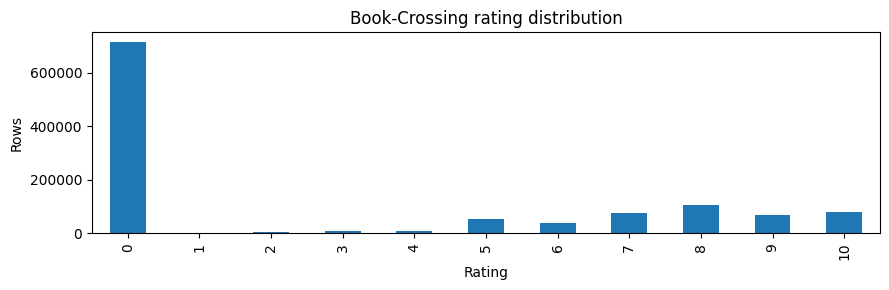

In [7]:
# Rating values: zero is not an explicit preference in this dataset.
rating_values = pd.to_numeric(bronze["ratings"]["Book-Rating"], errors="coerce")
rating_distribution = rating_values.value_counts(dropna=False).sort_index()
display(rating_distribution.rename("number_of_rows").to_frame())

zero_count = int((rating_values == 0).sum())
valid_explicit_count = int(rating_values.between(1, 10).sum())
print(f"Zero ratings: {zero_count:,} ({zero_count / len(rating_values):.2%} of rating rows)")
print(f"Explicit ratings from 1 to 10: {valid_explicit_count:,}")

rating_distribution.dropna().plot(kind="bar", figsize=(9, 3), title="Book-Crossing rating distribution")
plt.xlabel("Rating")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()

**EDA note — ratings:** 716,109 ratings (62.28%) have a value of zero, while 433,671 ratings contain explicit scores between 1 and 10. Since zero represents no explicit rating, these records will be removed in Silver.


Age summary:


,age
count,168096.0
mean,34.751434
std,14.428097
min,0.0
25%,24.0
50%,32.0
75%,44.0
max,244.0


Missing / non-numeric ages: 110762
Ages below 5: 882
Ages above 100: 366


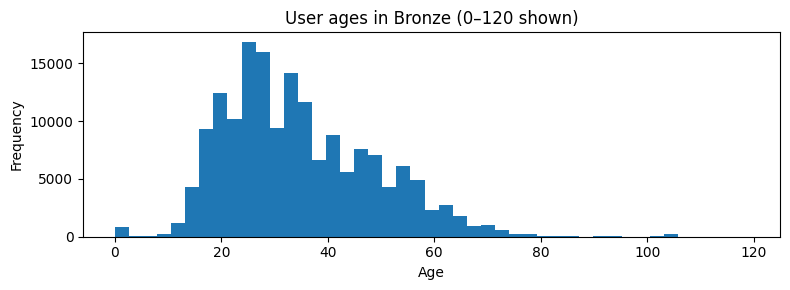

Publication-year summary:


,publication_year
count,271376.0
mean,1959.755594
std,258.012752
min,0.0
25%,1989.0
50%,1995.0
75%,2000.0
max,2050.0


Missing / non-numeric years: 3
Year equal to zero: 4619
Future years (after 2026): 11


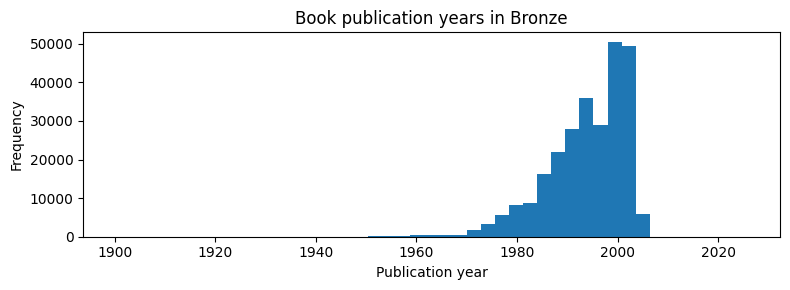

In [8]:
# User-age inspection, including impossible or implausible values.
age_values = pd.to_numeric(bronze["users"]["Age"], errors="coerce")
print("Age summary:")
display(age_values.describe().to_frame("age"))
print("Missing / non-numeric ages:", int(age_values.isna().sum()))
print("Ages below 5:", int((age_values < 5).sum()))
print("Ages above 100:", int((age_values > 100).sum()))

age_values[(age_values >= 0) & (age_values <= 120)].plot(
    kind="hist", bins=45, figsize=(8, 3), title="User ages in Bronze (0–120 shown)"
)
plt.xlabel("Age")
plt.tight_layout()
plt.show()

# Publication-year inspection.
year_values = pd.to_numeric(bronze["books"]["Year-Of-Publication"], errors="coerce")
print("Publication-year summary:")
display(year_values.describe().to_frame("publication_year"))
print("Missing / non-numeric years:", int(year_values.isna().sum()))
print("Year equal to zero:", int((year_values == 0).sum()))
print(f"Future years (after {CURRENT_YEAR}):", int((year_values > CURRENT_YEAR).sum()))

year_values[(year_values >= 1900) & (year_values <= CURRENT_YEAR)].plot(
    kind="hist", bins=45, figsize=(8, 3), title="Book publication years in Bronze"
)
plt.xlabel("Publication year")
plt.tight_layout()
plt.show()

**EDA note — ages and publication years:** There are 110,762 missing/non-numeric ages, 882 ages below 5 and 366 ages above 100. Publication years contain 4,618 zero values, 11 future values and 3 missing/non-numeric values. Silver will replace invalid ages with null before median imputation and set invalid publication years to null.


Explicit ratings per user:


,ratings_per_user
count,77805.0
mean,5.573819
std,44.001879
min,1.0
25%,1.0
50%,1.0
75%,3.0
max,8524.0


Explicit ratings per book:


,ratings_per_book
count,185973.0
mean,2.331903
std,6.834667
min,1.0
25%,1.0
50%,1.0
75%,2.0
max,707.0


,users_at_or_above,books_at_or_above
minimum_explicit_ratings,,
1,77805,185973
2,32423,56352
5,14220,14535
10,7334,5645
20,3704,2179
50,1332,537


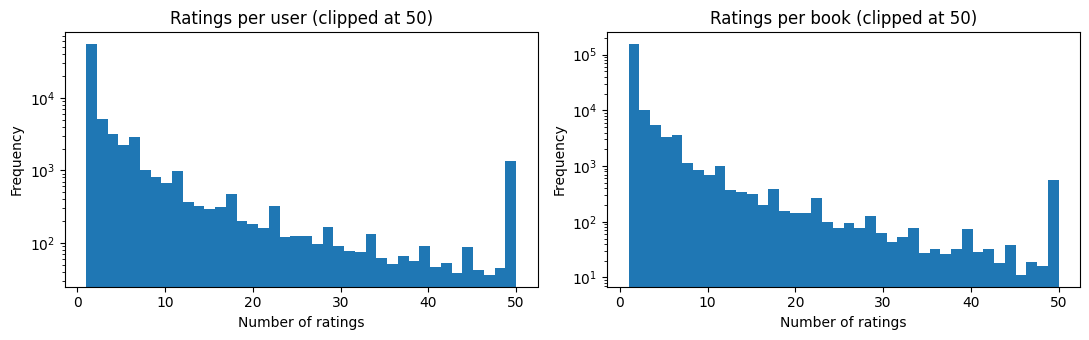

In [9]:
# Activity is measured using explicit ratings only.
explicit_bronze = bronze["ratings"].copy()
explicit_bronze["rating_numeric"] = rating_values
explicit_bronze = explicit_bronze[explicit_bronze["rating_numeric"].between(1, 10)]

user_activity = explicit_bronze["User-ID"].value_counts()
book_activity = explicit_bronze["ISBN"].value_counts()

print("Explicit ratings per user:")
display(user_activity.describe().to_frame("ratings_per_user"))
print("Explicit ratings per book:")
display(book_activity.describe().to_frame("ratings_per_book"))

activity_thresholds = [1, 2, 5, 10, 20, 50]
activity_table = pd.DataFrame({
    "users_at_or_above": [(user_activity >= t).sum() for t in activity_thresholds],
    "books_at_or_above": [(book_activity >= t).sum() for t in activity_thresholds],
}, index=activity_thresholds)
activity_table.index.name = "minimum_explicit_ratings"
display(activity_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
user_activity.clip(upper=50).plot(kind="hist", bins=40, ax=axes[0], logy=True, title="Ratings per user (clipped at 50)")
book_activity.clip(upper=50).plot(kind="hist", bins=40, ax=axes[1], logy=True, title="Ratings per book (clipped at 50)")
axes[0].set_xlabel("Number of ratings")
axes[1].set_xlabel("Number of ratings")
plt.tight_layout()
plt.show()

**EDA note — activity counts:** The median user and book each have only one explicit rating, showing a highly skewed activity distribution. Only 7,334 users and 5,645 books have at least 10 explicit ratings. Therefore, I selected a minimum threshold of 10 ratings and will apply it iteratively to retain sufficiently active users and books.


In [10]:
def report_matrix_sparsity(frame, user_col, book_col, label):
    user_total = frame[user_col].nunique()
    book_total = frame[book_col].nunique()
    possible_pairs = user_total * book_total
    observed_pairs = frame[[user_col, book_col]].drop_duplicates().shape[0]
    density = 100 * observed_pairs / possible_pairs if possible_pairs else 0
    sparsity = 100 - density
    print(
        f"{label}: {user_total:,} users × {book_total:,} books = {possible_pairs:,} possible pairs; "
        f"{observed_pairs:,} observed pairs; density={density:.5f}%; sparsity={sparsity:.5f}%"
    )

all_rating_pairs = bronze["ratings"].dropna(subset=["User-ID", "ISBN"])
explicit_rating_pairs = explicit_bronze.dropna(subset=["User-ID", "ISBN"])
report_matrix_sparsity(all_rating_pairs, "User-ID", "ISBN", "All source rating rows")
report_matrix_sparsity(explicit_rating_pairs, "User-ID", "ISBN", "Explicit ratings only")

All source rating rows: 105,283 users × 340,556 books = 35,854,757,348 possible pairs; 1,149,780 observed pairs; density=0.00321%; sparsity=99.99679%
Explicit ratings only: 77,805 users × 185,973 books = 14,469,629,265 possible pairs; 433,671 observed pairs; density=0.00300%; sparsity=99.99700%


**EDA note — matrix sparsity:** The explicit-rating matrix has 77,805 users and 185,973 books, with only 433,671 observed pairs out of 14,469,629,265 possible pairs. This gives approximately 99.997% sparsity. Therefore, Gold will store the rating matrix using CSR sparse representation instead of a dense matrix.


## 3. Clean the data and create the Silver layer

The cleaning logic below is applied independently to users, books and ratings. The final filter is performed after referential checks, and the activity threshold is iterated until every remaining user and book meets the selected minimum.

In [11]:
cleaning_log = []

def log_rows(stage, frame):
    cleaning_log.append({"stage": stage, "rows_remaining": len(frame)})
    print(f"{stage:<48} {len(frame):>12,}")


def clean_text(series, casing="title"):
    values = series.astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    values = values.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
    if casing == "title":
        return values.str.title()
    if casing == "upper":
        return values.str.upper()
    if casing == "lower":
        return values.str.lower()
    return values

### 3.1 Users: identifiers, duplicate rows, ages and locations

`Location` is split into city, state and country fields. Incomplete location strings are retained with missing components rather than being guessed.

In [12]:
users = bronze["users"].drop(columns="ingestion_timestamp").copy()
users = users.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
log_rows("Users read from Bronze", users)

users = users.drop_duplicates()
users["user_id"] = pd.to_numeric(users["user_id"], errors="coerce")
users = users.dropna(subset=["user_id"])
users["user_id"] = users["user_id"].astype("int64")
users = users.drop_duplicates(subset=["user_id"], keep="last")
log_rows("Users after duplicate / ID checks", users)

users["age"] = pd.to_numeric(users["age"], errors="coerce")
users.loc[(users["age"] < 5) | (users["age"] > 100), "age"] = np.nan
median_age = users["age"].median()
if pd.isna(median_age):
    median_age = 30
users["age"] = users["age"].fillna(median_age).round().astype("int64")

# Parse from the right: two-part locations are treated as city + country;
# the state remains missing when the source does not provide it.
location_parts = clean_text(users["location"], casing="lower").str.split(",")
users["city"] = clean_text(
    location_parts.map(lambda parts: parts[0] if isinstance(parts, list) and len(parts) >= 1 else pd.NA),
    casing="title",
)
users["state"] = clean_text(
    location_parts.map(lambda parts: parts[1] if isinstance(parts, list) and len(parts) >= 3 else pd.NA),
    casing="title",
)
users["country"] = clean_text(
    location_parts.map(lambda parts: parts[-1] if isinstance(parts, list) and len(parts) >= 2 else pd.NA),
    casing="title",
)
users = users.drop(columns="location")

for column in ("city", "state", "country"):
    users[column] = users[column].replace({"N/A": pd.NA, "Na": pd.NA, "Unknown": pd.NA, ".": pd.NA, "-": pd.NA})

users.head()

Users read from Bronze                                278,858
Users after duplicate / ID checks                     278,858


,user_id,age,city,state,country
0,1,32,Nyc,New York,Usa;Null
1,2,18,Stockton,California,Usa
2,3,32,Moscow,Yukon Territory,Russia;Null
3,4,17,Porto,V.N.Gaia,Portugal
4,5,32,Farnborough,Hants,United Kingdom;Null


### 3.2 Books: metadata, publication years and unused image links

ISBNs are normalised to uppercase. Publication years outside the valid range are set to missing. Image URLs are dropped because this assignment returns text recommendations only.

In [13]:
books = bronze["books"].drop(columns="ingestion_timestamp").copy()
books = books.rename(columns={
    "ISBN": "isbn",
    "Book-Title": "title",
    "Book-Author": "author",
    "Year-Of-Publication": "publication_year",
    "Publisher": "publisher",
})
books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"], errors="ignore")
log_rows("Books read from Bronze", books)

books = books.drop_duplicates()
books["isbn"] = clean_text(books["isbn"], casing="upper")
books["title"] = clean_text(books["title"], casing="title")
books["author"] = clean_text(books["author"], casing="title")
books["publisher"] = clean_text(books["publisher"], casing="title")
books = books.dropna(subset=["isbn"])
books = books.drop_duplicates(subset=["isbn"], keep="last")

books["publication_year"] = pd.to_numeric(books["publication_year"], errors="coerce")
invalid_year = (books["publication_year"] <= 0) | (books["publication_year"] > CURRENT_YEAR)
books.loc[invalid_year, "publication_year"] = np.nan
books["publication_year"] = books["publication_year"].astype("Int64")
books["title"] = books["title"].fillna("Unknown Title")
books["author"] = books["author"].fillna("Unknown Author")
log_rows("Books after cleaning", books)
books.head()

Books read from Bronze                                271,379
Books after cleaning                                  271,064


,isbn,title,author,publication_year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton &Amp; Company


### 3.3 Ratings: explicit scores, valid keys and one score per user–book pair

Zero means that no explicit score was given, so it is excluded. After duplicate removal and type conversion, ratings are restricted to 1–10 and to users/books present in their corresponding Silver tables. If a user–book pair has multiple distinct explicit scores, they are consolidated using the mean so that the Gold matrix has one value per pair.

In [14]:
ratings = bronze["ratings"].drop(columns="ingestion_timestamp").copy()
ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
log_rows("Ratings read from Bronze", ratings)

ratings = ratings.drop_duplicates()
ratings["user_id"] = pd.to_numeric(ratings["user_id"], errors="coerce")
ratings["rating"] = pd.to_numeric(ratings["rating"], errors="coerce")
ratings["isbn"] = clean_text(ratings["isbn"], casing="upper")
ratings = ratings.dropna(subset=["user_id", "isbn", "rating"])
ratings["user_id"] = ratings["user_id"].astype("int64")
ratings = ratings[ratings["rating"].between(1, 10)]
log_rows("Ratings after keeping explicit scores", ratings)

valid_user_ids = set(users["user_id"])
valid_isbns = set(books["isbn"])
ratings = ratings[
    ratings["user_id"].isin(valid_user_ids) & ratings["isbn"].isin(valid_isbns)
].copy()
log_rows("Ratings after referential-integrity checks", ratings)

ratings = (
    ratings.groupby(["user_id", "isbn"], as_index=False)["rating"]
    .mean()
)
ratings["rating"] = ratings["rating"].astype("float32")
log_rows("Ratings after consolidating user-book pairs", ratings)

Ratings read from Bronze                            1,149,780
Ratings after keeping explicit scores                 433,671
Ratings after referential-integrity checks            383,853
Ratings after consolidating user-book pairs           383,853


### 3.4 Iterative activity filter and write Silver Parquet files

**Chosen minimum:** 10 ratings per user and 10 ratings per book. The EDA table shows the long-tail activity distribution; a rating-count floor removes profiles/items with too little overlap for a meaningful item similarity calculation. The iterative loop maintains this rule after every removal.

In [15]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

while not ratings.empty:
    counts_by_user = ratings["user_id"].value_counts()
    counts_by_book = ratings["isbn"].value_counts()
    eligible = (
        ratings["user_id"].map(counts_by_user).ge(MIN_USER_RATINGS)
        & ratings["isbn"].map(counts_by_book).ge(MIN_BOOK_RATINGS)
    )
    if eligible.all():
        break
    ratings = ratings.loc[eligible].copy()

if ratings.empty:
    raise ValueError("No ratings remain. Revisit the minimum activity thresholds.")

users = users[users["user_id"].isin(ratings["user_id"].unique())].copy()
books = books[books["isbn"].isin(ratings["isbn"].unique())].copy()

users = users.reset_index(drop=True)
books = books.reset_index(drop=True)
ratings = ratings.reset_index(drop=True)

users.to_parquet(SILVER_DIR / "users.parquet", index=False)
books.to_parquet(SILVER_DIR / "books.parquet", index=False)
ratings.to_parquet(SILVER_DIR / "ratings.parquet", index=False)

print("\nSilver layer saved:")
for path in sorted(SILVER_DIR.glob("*.parquet")):
    print(f"{path}: {path.stat().st_size / (1024 ** 2):.2f} MB")

display(pd.DataFrame(cleaning_log))
print("Final Silver dimensions:", {"users": users.shape, "books": books.shape, "ratings": ratings.shape})


Silver layer saved:
silver/books.parquet: 0.07 MB
silver/ratings.parquet: 0.10 MB
silver/users.parquet: 0.03 MB


,stage,rows_remaining
0,Users read from Bronze,278858
1,Users after duplicate / ID checks,278858
2,Books read from Bronze,271379
3,Books after cleaning,271064
4,Ratings read from Bronze,1149780
5,Ratings after keeping explicit scores,433671
6,Ratings after referential-integrity checks,383853
7,Ratings after consolidating user-book pairs,383853


Final Silver dimensions: {'users': (1820, 5), 'books': (2030, 5), 'ratings': (41469, 3)}


## 4. Build the Gold layer

Gold contains the model-ready objects:

- A CSR sparse user × book rating matrix.
- User and book index tables that map matrix positions back to real IDs.
- A readable book lookup table.
- User-level and book-level average-rating and rating-count aggregates.

In [16]:
# Reload Silver outputs to keep the layer boundary explicit.
s_users = pd.read_parquet(SILVER_DIR / "users.parquet")
s_books = pd.read_parquet(SILVER_DIR / "books.parquet")
s_ratings = pd.read_parquet(SILVER_DIR / "ratings.parquet")

user_ids = np.sort(s_ratings["user_id"].unique())
book_isbns = np.sort(s_ratings["isbn"].unique())
user_to_row = {user_id: row for row, user_id in enumerate(user_ids)}
isbn_to_col = {isbn: col for col, isbn in enumerate(book_isbns)}

row_numbers = s_ratings["user_id"].map(user_to_row).to_numpy()
column_numbers = s_ratings["isbn"].map(isbn_to_col).to_numpy()

user_book_matrix = sparse.csr_matrix(
    (
        s_ratings["rating"].to_numpy(dtype=np.float32),
        (row_numbers, column_numbers),
    ),
    shape=(len(user_ids), len(book_isbns)),
    dtype=np.float32,
)

sparse.save_npz(GOLD_DIR / "user_book_matrix.npz", user_book_matrix)
user_index = pd.DataFrame({"row": np.arange(len(user_ids)), "user_id": user_ids})
book_index = pd.DataFrame({"col": np.arange(len(book_isbns)), "isbn": book_isbns})
user_index.to_parquet(GOLD_DIR / "user_index.parquet", index=False)
book_index.to_parquet(GOLD_DIR / "book_index.parquet", index=False)

matrix_density = 100 * user_book_matrix.nnz / (user_book_matrix.shape[0] * user_book_matrix.shape[1])
print("Sparse matrix shape:", user_book_matrix.shape)
print("Stored ratings:", f"{user_book_matrix.nnz:,}")
print("Matrix density:", f"{matrix_density:.4f}%")

Sparse matrix shape: (1820, 2030)
Stored ratings: 41,469
Matrix density: 1.1224%


In [17]:
book_lookup = s_books[["isbn", "title", "author"]].drop_duplicates("isbn").copy()
book_lookup.to_parquet(GOLD_DIR / "book_lookup.parquet", index=False)

book_stats = (
    s_ratings.groupby("isbn")["rating"]
    .agg(average_rating="mean", number_of_ratings="count")
    .reset_index()
    .merge(book_lookup, on="isbn", how="left")
)
book_stats["average_rating"] = book_stats["average_rating"].round(2)
book_stats.to_parquet(GOLD_DIR / "book_stats.parquet", index=False)

user_stats = (
    s_ratings.groupby("user_id")["rating"]
    .agg(average_rating="mean", number_of_ratings="count")
    .reset_index()
    .merge(s_users[["user_id", "age", "city", "state", "country"]], on="user_id", how="left")
)
user_stats["average_rating"] = user_stats["average_rating"].round(2)
user_stats.to_parquet(GOLD_DIR / "user_stats.parquet", index=False)

print("Most frequently rated books in Gold:")
display(book_stats.sort_values("number_of_ratings", ascending=False).head(10))
print("\nGold files:")
for path in sorted(GOLD_DIR.iterdir()):
    print(path.name)

Most frequently rated books in Gold:


,isbn,average_rating,number_of_ratings,title,author
281,0316666343,8.24,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.61,177,The Da Vinci Code,Dan Brown
205,0312195516,8.49,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.66,125,The Secret Life Of Bees,Sue Monk Kidd
1520,059035342X,9.04,119,Harry Potter And The Sorcerer'S Stone (Harry P...,J. K. Rowling
1100,0446672211,8.30,115,Where The Heart Is (Oprah'S Book Club (Paperba...,Billie Letts
44,0060928336,8.12,113,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells
869,043935806X,9.07,111,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling
332,0345337662,7.71,105,Interview With The Vampire,Anne Rice
275,0316601950,7.79,101,The Pilot'S Wife : A Novel,Anita Shreve



Gold files:
book_index.parquet
book_lookup.parquet
book_stats.parquet
user_book_matrix.npz
user_index.parquet
user_stats.parquet


## 5. Item-based collaborative filtering

A book is represented by its vector of ratings across users. Books with similar rating patterns have a smaller cosine distance. We transpose the Gold matrix so that **each row represents a book and each column represents a user**, then retrieve nearest neighbours using cosine distance.

In [18]:
# Load the matrix and mapping files from Gold rather than reusing in-memory objects.
R = sparse.load_npz(GOLD_DIR / "user_book_matrix.npz").tocsr()
user_index = pd.read_parquet(GOLD_DIR / "user_index.parquet")
book_index = pd.read_parquet(GOLD_DIR / "book_index.parquet")
book_lookup = pd.read_parquet(GOLD_DIR / "book_lookup.parquet")
book_stats = pd.read_parquet(GOLD_DIR / "book_stats.parquet")
user_stats = pd.read_parquet(GOLD_DIR / "user_stats.parquet")

item_user_matrix = R.T.tocsr()

# Position -> ISBN/title/author mappings used by the recommendation functions.
column_isbns = book_index.sort_values("col")["isbn"].to_numpy()
user_row = dict(zip(user_index["user_id"], user_index["row"]))
info_by_isbn = book_lookup.set_index("isbn").reindex(column_isbns)
column_titles = info_by_isbn["title"].fillna("Unknown Title").to_numpy()
column_authors = info_by_isbn["author"].fillna("Unknown Author").to_numpy()
column_by_isbn = {isbn: col for col, isbn in enumerate(column_isbns)}

print("Book-user matrix:", item_user_matrix.shape)

Book-user matrix: (2030, 1820)


### 5.1 Fit cosine nearest neighbours

The model stores up to 26 neighbours for each book (including the book itself). This is enough to return a top-10 similar-book list while keeping the neighbour table compact.

In [19]:
NEIGHBOUR_COUNT = min(26, item_user_matrix.shape[0])
if NEIGHBOUR_COUNT < 2:
    raise ValueError("At least two books are required to calculate book similarities.")

item_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=NEIGHBOUR_COUNT,
)
item_model.fit(item_user_matrix)

neighbour_distances, neighbour_indices = item_model.kneighbors(item_user_matrix)
print("Neighbour index array:", neighbour_indices.shape)
print("Cosine similarity is calculated as 1 - cosine distance.")

Neighbour index array: (2030, 26)
Cosine similarity is calculated as 1 - cosine distance.


### 5.2 Find a book and return its nearest similar titles

Title matching is case-insensitive. Partial title searches are accepted; when multiple editions share a title, the edition with the larger rating count is selected.

In [20]:
def resolve_book_isbn(query):
    query = str(query).strip().casefold()
    if not query:
        raise ValueError("Enter a non-empty book title.")

    title_series = book_lookup["title"].fillna("").astype(str)
    exact = book_lookup[title_series.str.casefold() == query]
    candidates = exact if not exact.empty else book_lookup[
        title_series.str.casefold().str.contains(query, regex=False, na=False)
    ]

    if candidates.empty:
        raise ValueError(f"No book title matched: {query!r}")

    candidates = candidates.merge(
        book_stats[["isbn", "number_of_ratings"]], on="isbn", how="left"
    )
    return candidates.sort_values("number_of_ratings", ascending=False).iloc[0]["isbn"]


def similar_books(title, n=10):
    isbn = resolve_book_isbn(title)
    source_col = column_by_isbn[isbn]
    rows = []
    used_titles = {str(column_titles[source_col]).casefold()}

    for neighbour_col, distance in zip(
        neighbour_indices[source_col], neighbour_distances[source_col]
    ):
        if neighbour_col == source_col:
            continue
        candidate_title = str(column_titles[neighbour_col])
        title_key = candidate_title.casefold()
        if title_key in used_titles:
            continue

        used_titles.add(title_key)
        rows.append({
            "similar_book": candidate_title,
            "author": column_authors[neighbour_col],
            "cosine_similarity": round(float(1 - distance), 4),
        })
        if len(rows) >= n:
            break

    return pd.DataFrame(rows)

popular_title = book_stats.sort_values("number_of_ratings", ascending=False).iloc[0]["title"]
print("Example input title:", popular_title)
display(similar_books(popular_title, n=10))

Example input title: The Lovely Bones: A Novel


,similar_book,author,cosine_similarity
0,Where The Heart Is (Oprah'S Book Club (Paperba...,Billie Letts,0.2192
1,Lucky : A Memoir,Alice Sebold,0.2180
2,The Da Vinci Code,Dan Brown,0.1783
3,The Pilot'S Wife : A Novel,Anita Shreve,0.1763
4,Good In Bed,Jennifer Weiner,0.1758
5,Nights In Rodanthe,Nicholas Sparks,0.1702
6,The Pact: A Love Story,Jodi Picoult,0.1682
7,The Lake House,James Patterson,0.1662
8,Lucky,Alice Sebold,0.1651
9,White Oleander : A Novel (Oprah'S Book Club),Janet Fitch,0.1542


### 5.3 Recommend books for a user

The recommendation score is the sum of each candidate book's similarity to a liked book multiplied by the user's rating for that liked book. Books already rated by the user are removed. Different ISBN editions of a title are also treated as the same title to avoid duplicate-looking recommendations.

In [21]:
LIKED_RATING_CUTOFF = 8


def get_user_preferences(user_id, cutoff=LIKED_RATING_CUTOFF):
    if user_id not in user_row:
        raise KeyError(f"User {user_id} is not part of the filtered Gold dataset.")

    user_ratings = R.getrow(user_row[user_id])
    rated = pd.DataFrame({
        "book_col": user_ratings.indices,
        "rating": user_ratings.data.astype(float),
    })
    liked = rated[rated["rating"] >= cutoff].copy()

    # If the user has no rating >= 8, use their maximum-rated books instead.
    if liked.empty and not rated.empty:
        liked = rated[rated["rating"] == rated["rating"].max()].copy()

    return rated, liked.sort_values("rating", ascending=False)


def recommend(user_id, n=10):
    rated, liked = get_user_preferences(user_id)
    if rated.empty or liked.empty:
        return pd.DataFrame(columns=["recommended_title", "author", "score"])

    read_columns = set(rated["book_col"].astype(int))
    read_title_keys = {str(column_titles[col]).casefold() for col in read_columns}
    candidate_scores = defaultdict(float)

    for source_col, user_rating in zip(liked["book_col"], liked["rating"]):
        for candidate_col, distance in zip(
            neighbour_indices[int(source_col)], neighbour_distances[int(source_col)]
        ):
            similarity = float(1 - distance)
            if candidate_col in read_columns or similarity <= 0:
                continue
            candidate_scores[int(candidate_col)] += similarity * float(user_rating)

    ranked_candidates = sorted(
        candidate_scores.items(), key=lambda pair: pair[1], reverse=True
    )

    recommendations = []
    seen_titles = set(read_title_keys)
    for candidate_col, score in ranked_candidates:
        candidate_title = str(column_titles[candidate_col])
        title_key = candidate_title.casefold()
        if title_key in seen_titles:
            continue
        seen_titles.add(title_key)
        recommendations.append({
            "recommended_title": candidate_title,
            "author": column_authors[candidate_col],
            "score": round(float(score), 4),
        })
        if len(recommendations) >= n:
            break

    return pd.DataFrame(recommendations)

## 6. Demonstration and sanity checks

Three profiles are selected from the filtered user population: one with many ratings, one around the middle of the activity distribution, and one with the minimum activity. For each user, compare their highly rated books with the generated recommendations.

In [22]:
ranked_user_stats = user_stats.sort_values("number_of_ratings", ascending=False).reset_index(drop=True)
positions = sorted(set([0, len(ranked_user_stats) // 2, len(ranked_user_stats) - 1]))
demo_user_ids = [int(ranked_user_stats.loc[position, "user_id"]) for position in positions]
print("Selected demonstration users:", demo_user_ids)

Selected demonstration users: [11676, 192245, 805]


In [23]:
def display_user_demo(user_id, n=10):
    rated, liked = get_user_preferences(user_id)
    favourite_rows = [
        {
            "favourite_book": column_titles[int(col)],
            "user_rating": round(float(rating), 1),
        }
        for col, rating in zip(liked["book_col"].head(n), liked["rating"].head(n))
    ]
    favourites = pd.DataFrame(favourite_rows)
    recommendations = recommend(user_id, n=n)

    print(
        f"\nUser {user_id} | explicit ratings: {len(rated)} | "
        f"liked books used: {len(liked)}"
    )
    comparison = pd.concat(
        [favourites.reset_index(drop=True), recommendations.reset_index(drop=True)],
        axis=1,
    )
    display(comparison.fillna(""))
    return rated, recommendations


demo_results = {}
for demo_id in demo_user_ids:
    demo_results[demo_id] = display_user_demo(demo_id, n=10)


User 11676 | explicit ratings: 954 | liked books used: 607


,favourite_book,user_rating,recommended_title,author,score
0,The Time Traveler'S Wife (Today Show Book Club...,10.0,"Night Shield (Intimate Moments, 1027)",Nora Roberts,54.6971
1,The Time Traveler'S Wife,10.0,Palomino,Danielle Steel,47.6405
2,Tipping The Velvet,10.0,A Perfect Stranger,Danielle Steel,41.9569
3,The Poisonwood Bible,10.0,Night Tales,Nora Roberts,40.0592
4,Daughter Of Fortune : A Novel (Oprah'S Book Cl...,10.0,Public Secrets,Nora Roberts,38.8056
5,Prodigal Summer,10.0,Birthright,Nora Roberts,37.6761
6,The Color Of Water: A Black Man'S Tribute To H...,10.0,Stanislaski Brothers (Silhouette Promo),Nora Roberts,34.1293
7,I Know This Much Is True (Oprah'S Book Club),10.0,Summer'S End,Danielle Steel,32.8129
8,Soul Harvest: The World Takes Sides (Left Behi...,10.0,Tears Of The Moon (Irish Trilogy),Nora Roberts,31.5973
9,Tribulation Force: The Continuing Drama Of Tho...,10.0,Darkest Hour (Cutler),V.C. Andrews,27.9226



User 192245 | explicit ratings: 16 | liked books used: 8


,favourite_book,user_rating,recommended_title,author,score
0,Chosen Prey,9.0,Kiss The Girls,James Patterson,5.9616
1,Mortal Prey,9.0,Pop Goes The Weasel,James Patterson,5.2540
2,Roses Are Red (Alex Cross Novels),9.0,Along Came A Spider (Alex Cross Novels),James Patterson,4.9954
3,The Pilot'S Wife : A Novel,8.0,Four Blind Mice,James Patterson,4.9922
4,A Time To Kill,8.0,2Nd Chance,James Patterson,4.9005
5,1St To Die: A Novel,8.0,Writ Of Execution,Perri O'Shaughnessy,4.6875
6,Violets Are Blue,8.0,Jack &Amp; Jill (Alex Cross Novels),James Patterson,4.5428
7,Left Behind: A Novel Of The Earth'S Last Days ...,8.0,Tribulation Force: The Continuing Drama Of Tho...,Tim Lahaye,4.2830
8,,,Nicolae: The Rise Of Antichrist (Left Behind N...,Tim F. Lahaye,4.1093
9,,,The Mark: The Beast Rules The World (Left Behi...,Tim Lahaye,3.9466



User 805 | explicit ratings: 10 | liked books used: 8


,favourite_book,user_rating,recommended_title,author,score
0,Where The Sidewalk Ends : Poems And Drawings,10.0,The Talented Mr. Ripley (Vintage Crime/Black L...,Patricia Highsmith,4.8190
1,Writing Down The Bones,10.0,Balzac And The Little Chinese Seamstress : A N...,Dai Sijie,4.3848
2,Interpreter Of Maladies,9.0,Bastard Out Of Carolina,Dorothy Allison,4.3488
3,Life Of Pi,9.0,Voyager,Diana Gabaldon,4.2817
4,Dragonfly In Amber,8.0,Outlander,Diana Gabaldon,4.1678
5,Girl With A Pearl Earring,8.0,Drums Of Autumn,Diana Gabaldon,4.0588
6,Jitterbug Perfume,8.0,How The Garcia Girls Lost Their Accents (Plume...,Julia Alvarez,3.5952
7,She'S Come Undone (Oprah'S Book Club (Paperback)),8.0,One Hundred Years Of Solitude,Gabriel Garcia Marquez,3.1244
8,,,I Know Why The Caged Bird Sings,Maya Angelou,3.1142
9,,,Tulip Fever,Deborah Moggach,2.9949


In [24]:
# Basic sanity checks: recommendations should not repeat books already rated by the user.
for demo_id, (rated_frame, recommendation_frame) in demo_results.items():
    read_titles = {
        str(column_titles[int(col)]).casefold()
        for col in rated_frame["book_col"].tolist()
    }
    recommended_titles = recommendation_frame["recommended_title"].astype(str).str.casefold().tolist()
    assert not (read_titles & set(recommended_titles)), f"A previously read title was recommended to user {demo_id}."
    assert len(recommended_titles) == len(set(recommended_titles)), f"Duplicate recommendation title for user {demo_id}."

print("Sanity checks passed: no already-rated titles or duplicate titles in the displayed recommendation lists.")

Sanity checks passed: no already-rated titles or duplicate titles in the displayed recommendation lists.


## 7. Findings, limitations and conclusion

The final recommendation list is based on patterns of explicit ratings shared by users. The preprocessing steps remove zero ratings, enforce referential integrity, and trim the least-active users and books so the model has a more useful overlap of rating histories.

**Limitations**

- **Cold start:** users and books below the activity threshold are excluded; a new user or book has no collaborative history to compare.
- **Popularity bias:** frequently rated books can share many raters and may appear often in recommendation lists.
- **Sparse feedback:** many user–book pairs remain unobserved, and zero ratings are not treated as explicit negative preferences.
- **No offline accuracy estimate:** this assignment evaluates the pipeline through EDA and sanity-check examples. A separate train/test split with ranking metrics such as Precision@K or Recall@K would be needed to estimate predictive quality.

**Conclusion:** the notebook implements the complete Bronze–Silver–Gold workflow and uses item-based cosine similarity to generate readable top-N book recommendations for existing users.